# Arquitectura ResNet18 para clasificación de flores

Registro de entrenamiento y evaluación en GPU Tesla T4. Se compararon seis configuraciones, se seleccionó E5_LAYER4 por validación y se exportó el modelo final con sus metadatos y evidencias. Las salidas conservadas documentan esta ejecución.

## 1. Importaciones, dependencias y reproducibilidad

In [1]:
import sys, os, time, json, random, platform, gc, copy
from pathlib import Path
from importlib import metadata
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import torch
from torch import nn
from torch.utils.data import DataLoader
from torchvision import datasets, models
from sklearn.metrics import (accuracy_score, confusion_matrix, classification_report,
                             precision_recall_fscore_support)
ROOT = Path('/content/flowers102_reentrenamiento_independiente') if Path('/content').exists() else Path.cwd() / 'flowers102_reentrenamiento_independiente'
ROOT.mkdir(parents=True, exist_ok=True)
CKPT_DIR = ROOT / 'checkpoints'
CKPT_DIR.mkdir(exist_ok=True)
EVID_DIR = ROOT / 'evidencias'
EVID_DIR.mkdir(exist_ok=True)
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
NUM_WORKERS = 2  # Lectura paralela; reducir a 0 si el entorno no admite subprocesos
def seed_all(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
def package_version(pkg):
    try:
        return metadata.version(pkg)
    except metadata.PackageNotFoundError:
        return 'NO INSTALADO'
assert DEVICE.type == 'cuda', ('Este reentrenamiento requiere GPU CUDA para evitar ejecutar de nuevo ~2 horas en CPU. En Colab selecciona Entorno de ejecución > Cambiar tipo de entorno > GPU. Si no existe disponibilidad, no se inicia el entrenamiento.')
print('GPU:', torch.cuda.get_device_name(0))
seed_all(42)
VERSIONS = {'python': sys.version.split()[0], 'torch': torch.__version__,
            'torchvision': package_version('torchvision'), 'numpy': np.__version__,
            'matplotlib': package_version('matplotlib'), 'pandas': pd.__version__,
            'scikit-learn': package_version('scikit-learn')}
print('[1/10] Entorno:', platform.platform(), '| Dispositivo:', DEVICE)
for k,v in VERSIONS.items(): print(' ',k,'=',v)
print('Directorio de salida:', ROOT.resolve())


GPU: Tesla T4
[1/10] Entorno: Linux-6.6.159+-x86_64-with-glibc2.39 | Dispositivo: cuda
  python = 3.13.16
  torch = 2.14.1+cu130
  torchvision = 0.29.1+cu130
  numpy = 2.4.6
  matplotlib = 3.10.0
  pandas = 2.2.3
  scikit-learn = 1.6.1
Directorio de salida: /content/flowers102_reentrenamiento_independiente


### Importaciones y reproducibilidad
1. `torch` gestiona tensores y autograd; `torch.nn`, capas y pérdidas; `torchvision`, Flowers102, transformaciones y ResNet18; NumPy, arreglos; matplotlib, gráficas; pandas, tablas; scikit-learn, métricas; pathlib, rutas. `torch.device` determina CPU o CUDA. El entorno registrado utilizó Tesla T4 y CUDA.
2. E1 cambió solo la semilla de 42 a 7: validación pasó de 75.6863% a 76.3725%, una diferencia de +0.6863 puntos porcentuales. Los tiempos fueron 65.29 s y 62.91 s. Una sola repetición no demuestra estabilidad estadística ni igualdad entre dispositivos.

## 2. Dataset, transformaciones y particiones

In [2]:
print('[2/10] Descargando o leyendo Oxford Flowers102 y pesos oficiales...')
PESOS = models.ResNet18_Weights.DEFAULT
TRANSFORM = PESOS.transforms()
DATA_ROOT = ROOT / 'datos'
train_ds = datasets.Flowers102(str(DATA_ROOT), split='train', download=True, transform=TRANSFORM)
val_ds = datasets.Flowers102(str(DATA_ROOT), split='val', download=True, transform=TRANSFORM)
test_ds = datasets.Flowers102(str(DATA_ROOT), split='test', download=True, transform=TRANSFORM)
NUM_CLASSES = 102
CLASSES = [f'Flor {i+1}' for i in range(NUM_CLASSES)]
assert len(train_ds)>0 and len(val_ds)>0 and len(test_ds)>0, 'Partición vacía'

def labels_of(dataset):
    # Flowers102 expone labels como atributo de la implementación actual;
    # alternativa genérica por acceso a ejemplos si cambia la versión.
    if hasattr(dataset, '_labels'):
        return np.asarray(dataset._labels, dtype=int)
    return np.asarray([int(dataset[i][1]) for i in range(len(dataset))], dtype=int)

LABELS = {'train': labels_of(train_ds), 'val': labels_of(val_ds), 'test': labels_of(test_ds)}
for split, ds in [('train',train_ds),('val',val_ds),('test',test_ds)]:
    y=LABELS[split]
    assert len(y)==len(ds), f'Etiquetas no coinciden con {split}'
    assert y.min()>=0 and y.max()<NUM_CLASSES, f'Índice fuera de rango: {split}'
    conteos = np.bincount(y, minlength=NUM_CLASSES)
    print(f'{split}: {len(ds)} imágenes; {np.count_nonzero(conteos)} clases; min/clase={conteos.min()}, max/clase={conteos.max()}')

sample_x, sample_y = train_ds[0]
assert tuple(sample_x.shape)==(3,224,224), f'Entrada inesperada: {sample_x.shape}'
print('Ejemplo de imagen transformada:',tuple(sample_x.shape),'| etiqueta:',sample_y)
print('Transformación efectiva:',TRANSFORM)
# Verificación por identidad de archivos, cuando la estructura de torchvision expone listas de imágenes.
if all(hasattr(x,'_image_files') for x in [train_ds,val_ds,test_ds]):
    id_sets=[set(map(str, x._image_files)) for x in [train_ds,val_ds,test_ds]]
    assert not(id_sets[0]&id_sets[1] or id_sets[0]&id_sets[2] or id_sets[1]&id_sets[2]), 'Rutas repetidas entre splits'
    print('Verificación de rutas: particiones disjuntas')
else:
    print('Advertencia: no se inspeccionaron las rutas originales; se utilizan los splits oficiales de torchvision')
print('[2/10] Datos preparados; prueba no se usará hasta finalizar la selección')

[2/10] Descargando o leyendo Oxford Flowers102 y pesos oficiales...


100%|██████████| 345M/345M [00:13<00:00, 25.3MB/s]
100%|██████████| 502/502 [00:00<00:00, 1.02MB/s]
100%|██████████| 15.0k/15.0k [00:00<00:00, 20.0MB/s]


train: 1020 imágenes; 102 clases; min/clase=10, max/clase=10
val: 1020 imágenes; 102 clases; min/clase=10, max/clase=10
test: 6149 imágenes; 102 clases; min/clase=20, max/clase=238
Ejemplo de imagen transformada: (3, 224, 224) | etiqueta: 0
Transformación efectiva: ImageClassification(
    crop_size=[224]
    resize_size=[256]
    mean=[0.485, 0.456, 0.406]
    std=[0.229, 0.224, 0.225]
    interpolation=InterpolationMode.BILINEAR
)
Verificación de rutas: particiones disjuntas
[2/10] Datos preparados; prueba no se usará hasta finalizar la selección


### Datos y particiones
1. Flowers102 contiene 102 clases: entrenamiento 1,020 imágenes (10 por clase), validación 1,020 (10 por clase) y prueba 6,149 (entre 20 y 238 por clase). Se registraron tensores RGB de 3 × 224 × 224 y particiones sin rutas compartidas. Entrenamiento actualiza pesos; validación selecciona configuraciones; prueba mide el desempeño después de la selección.
2. E2 elevó el lote de 32 a 64: validación disminuyó de 75.6863% a 73.4314% (−2.2549 puntos), mientras el tiempo pasó de 65.29 s a 60.63 s. En esta ejecución, el menor tiempo vino acompañado de menor exactitud. Ajustar configuraciones con prueba sesgaría la evaluación.

## 3. Configuración de ResNet18 y auditoría de arquitectura

In [3]:
print('[3/10] Definiendo ResNet18 y auditoría de arquitectura...')

def build_model(finetune_layer4=False):
    net = models.resnet18(weights=PESOS)
    for p in net.parameters(): p.requires_grad = False
    features = net.fc.in_features
    assert features==512, f'Se esperaban 512 características y se obtuvieron {features}'
    net.fc = nn.Linear(features,NUM_CLASSES)
    if finetune_layer4:
        for p in net.layer4.parameters(): p.requires_grad = True
    return net.to(DEVICE)

def audit_model(net, print_details=True):
    total=sum(p.numel() for p in net.parameters())
    trainable=sum(p.numel() for p in net.parameters() if p.requires_grad)
    frozen=total-trainable
    shapes=[]
    hooks=[]
    def register(name):
        def hook(module, x, y):
            shapes.append((name,tuple(x[0].shape),tuple(y.shape)))
        return hook
    prior=net.training
    try:
        for name, module in net.named_children():
            hooks.append(module.register_forward_hook(register(name)))
        net.eval()
        with torch.no_grad():
            out=net(torch.zeros(1,3,224,224,device=DEVICE))
        assert tuple(out.shape)==(1,NUM_CLASSES),f'Salida inesperada {out.shape}'
    finally:
        for hook in hooks:hook.remove()
        net.train(prior)
    result={'total':total,'trainable':trainable,'frozen':frozen,
            'components':shapes}
    if print_details:
        print('Parámetros:', {k:v for k,v in result.items() if k!='components'})
        for name,x,y in shapes:print(f'  {name:10} {x} -> {y}')
    return result

modelo_base = build_model(False)
ARQUITECTURA_BASE=audit_model(modelo_base)
assert ARQUITECTURA_BASE['total']==11228838
assert ARQUITECTURA_BASE['trainable']==52326
print('Auditoría base verificada; 102 salidas')
del modelo_base
gc.collect()
if DEVICE.type=='cuda':torch.cuda.empty_cache()

[3/10] Definiendo ResNet18 y auditoría de arquitectura...
Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 174MB/s]


Parámetros: {'total': 11228838, 'trainable': 52326, 'frozen': 11176512}
  conv1      (1, 3, 224, 224) -> (1, 64, 112, 112)
  bn1        (1, 64, 112, 112) -> (1, 64, 112, 112)
  relu       (1, 64, 112, 112) -> (1, 64, 112, 112)
  maxpool    (1, 64, 112, 112) -> (1, 64, 56, 56)
  layer1     (1, 64, 56, 56) -> (1, 64, 56, 56)
  layer2     (1, 64, 56, 56) -> (1, 128, 28, 28)
  layer3     (1, 128, 28, 28) -> (1, 256, 14, 14)
  layer4     (1, 256, 14, 14) -> (1, 512, 7, 7)
  avgpool    (1, 512, 7, 7) -> (1, 512, 1, 1)
  fc         (1, 512) -> (1, 102)
Auditoría base verificada; 102 salidas


### Arquitectura y decisiones de diseño
1. La entrada `(1,3,224,224)` recorre `conv1 (1,64,112,112)`, `maxpool (1,64,56,56)`, `layer1 (1,64,56,56)`, `layer2 (1,128,28,28)`, `layer3 (1,256,14,14)`, `layer4 (1,512,7,7)`, `avgpool (1,512,1,1)`, aplanado `(1,512)` y `fc (1,102)`. Los hooks registraron las formas del modelo. Total: 11,228,838 parámetros; base: 52,326 entrenables; E5: 8,446,054 entrenables.
2. `CrossEntropyLoss` recibe logits y etiquetas; ReLU añade no linealidad. `softmax` se utiliza para presentar probabilidades, no antes de la pérdida. Adam utiliza LR 0.001 en B0 y E5.
3. E3 redujo LR a 0.0001 y obtuvo 18.3333% de validación; E4 amplió a 10 épocas y obtuvo 83.4314%; E5 descongeló layer4 y obtuvo 91.9608%. Frente a B0, los cambios fueron −57.3529, +7.7451 y +16.2745 puntos porcentuales, respectivamente.

## 4. Entrenamiento y experimentos controlados

In [4]:
print('[4/10] Configurando los experimentos (sin usar test)...')
EXPERIMENTS = [
    {'id':'B0','seed':42,'batch_size':32,'lr':0.001,'epochs':5,'finetune_layer4':False},
    {'id':'E1_SEMILLA','seed':7,'batch_size':32,'lr':0.001,'epochs':5,'finetune_layer4':False},
    {'id':'E2_LOTE','seed':42,'batch_size':64,'lr':0.001,'epochs':5,'finetune_layer4':False},
    {'id':'E3_LR','seed':42,'batch_size':32,'lr':0.0001,'epochs':5,'finetune_layer4':False},
    {'id':'E4_EPOCAS','seed':42,'batch_size':32,'lr':0.001,'epochs':10,'finetune_layer4':False},
    {'id':'E5_LAYER4','seed':42,'batch_size':32,'lr':0.001,'epochs':5,'finetune_layer4':True},
]
assert len({x['id'] for x in EXPERIMENTS})==len(EXPERIMENTS)

def loaders(batch_size, seed):
    g=torch.Generator().manual_seed(seed)
    return (DataLoader(train_ds,batch_size=batch_size,shuffle=True,generator=g,num_workers=NUM_WORKERS),
            DataLoader(val_ds,batch_size=batch_size,shuffle=False,num_workers=NUM_WORKERS))

def eval_loader(net, loader, loss_fn):
    net.eval()
    losses=0.0;correct=0;total=0
    with torch.no_grad():
        for x,y in loader:
            x,y=x.to(DEVICE),y.to(DEVICE)
            logits=net(x)
            losses+=loss_fn(logits,y).item()*len(y)
            correct+=(logits.argmax(1)==y).sum().item()
            total+=len(y)
    return {'loss':losses/total,'accuracy':correct/total}

def train_one(cfg):
    seed_all(cfg['seed'])
    net=build_model(cfg['finetune_layer4'])
    train_loader,val_loader=loaders(cfg['batch_size'],cfg['seed'])
    loss_fn=nn.CrossEntropyLoss()
    opt=torch.optim.Adam([p for p in net.parameters() if p.requires_grad],lr=cfg['lr'])
    audit=audit_model(net,print_details=False)
    path=CKPT_DIR / f"{cfg['id']}_best.pth"
    history=[];best_acc=-1.;best_val_loss=float('inf');best_epoch=0
    start=time.perf_counter()
    try:
        for epoch in range(1,cfg['epochs']+1):
            net.train()
            # Mantener estadísticas de BatchNorm congeladas cuando sus pesos están congelados.
            # Con fine-tuning, layer4 permanece en modo entrenamiento; el resto queda fijo.
            for name, module in net.named_modules():
                if isinstance(module,nn.modules.batchnorm._BatchNorm):
                    if not any(p.requires_grad for p in module.parameters()):
                        module.eval()
            train_sum=0.0;seen=0
            for x,y in train_loader:
                x,y=x.to(DEVICE),y.to(DEVICE)
                opt.zero_grad(set_to_none=True)
                logits=net(x)
                loss=loss_fn(logits,y)
                loss.backward()
                opt.step()
                train_sum+=loss.item()*len(y);seen+=len(y)
            metrics=eval_loader(net,val_loader,loss_fn)
            train_loss=train_sum/seen
            history.append({'epoch':epoch,'train_loss':train_loss,
                            'val_loss':metrics['loss'],'val_acc':metrics['accuracy']})
            improved=(metrics['accuracy']>best_acc or
                      (metrics['accuracy']==best_acc and metrics['loss']<best_val_loss))
            if improved:
                best_acc=metrics['accuracy'];best_val_loss=metrics['loss'];best_epoch=epoch
                torch.save({'state_dict':net.state_dict(),'config':cfg,'epoch':epoch,
                            'val_accuracy':best_acc,'val_loss':best_val_loss,
                            'architecture':{'model':'resnet18','classes':CLASSES,'weights':'DEFAULT',
                                            'trainable':audit['trainable'],'total':audit['total']}},path)
            print(f"  {cfg['id']} | época {epoch}/{cfg['epochs']} | pérdida train={train_loss:.4f} | "
                  f"val_loss={metrics['loss']:.4f} | val_acc={metrics['accuracy']:.4f} "
                  f"| mejor época={best_epoch}",flush=True)
        duration=time.perf_counter()-start
        return {'id':cfg['id'],**cfg,'best_val_acc':best_acc,'best_val_loss':best_val_loss,
                'best_epoch':best_epoch,'seconds':duration,'trainable':audit['trainable'],
                'checkpoint':str(path),'history':history}
    finally:
        del net,opt
        gc.collect()
        if DEVICE.type=='cuda':torch.cuda.empty_cache()

print(f'Experimentos preparados: {len(EXPERIMENTS)}. Cada uno inicia desde pesos preentrenados y semilla declarada.')

[4/10] Configurando los experimentos (sin usar test)...
Experimentos preparados: 6. Cada uno inicia desde pesos preentrenados y semilla declarada.


### Entrenamiento
1. `zero_grad()` limpia gradientes, `backward()` calcula los de la pérdida y `step()` actualiza parámetros. El orden evita aplicar o acumular gradientes incorrectamente.
2. `train()` y `eval()` controlan el comportamiento de determinadas capas; `no_grad()` desactiva el registro de gradientes. En el código, BatchNorm de capas congeladas queda en evaluación; BatchNorm de layer4 permanece en entrenamiento cuando se habilita su ajuste.
3. E4 pasó de 5 a 10 épocas: validación aumentó de 75.6863% a 83.4314% y su pérdida final fue 1.1090 frente a 1.7359 de B0. Su pérdida de validación descendió globalmente hasta la época 10; no presenta deterioro sostenido que permita afirmar sobreajuste en ese intervalo.

In [5]:
print('[5/10] INICIO DE ENTRENAMIENTOS: 6 configuraciones; se registrará cada época.')
RESULTS=[]
for index,cfg in enumerate(EXPERIMENTS,1):
    print(f'\n>>> Experimento {index}/{len(EXPERIMENTS)}: {cfg}',flush=True)
    record=train_one(cfg)
    RESULTS.append(record)
    print(f"<<< Terminado {record['id']} | mejor val_acc={record['best_val_acc']:.4f} "
          f"| época={record['best_epoch']} | segundos={record['seconds']:.1f}",flush=True)
print('[5/10] Todos los entrenamientos completados')

[5/10] INICIO DE ENTRENAMIENTOS: 6 configuraciones; se registrará cada época.

>>> Experimento 1/6: {'id': 'B0', 'seed': 42, 'batch_size': 32, 'lr': 0.001, 'epochs': 5, 'finetune_layer4': False}
  B0 | época 1/5 | pérdida train=4.5653 | val_loss=3.8607 | val_acc=0.2245 | mejor época=1
  B0 | época 2/5 | pérdida train=3.2869 | val_loss=2.9892 | val_acc=0.5324 | mejor época=2
  B0 | época 3/5 | pérdida train=2.3864 | val_loss=2.4240 | val_acc=0.6422 | mejor época=3
  B0 | época 4/5 | pérdida train=1.7973 | val_loss=2.0154 | val_acc=0.7333 | mejor época=4
  B0 | época 5/5 | pérdida train=1.3747 | val_loss=1.7359 | val_acc=0.7569 | mejor época=5
<<< Terminado B0 | mejor val_acc=0.7569 | época=5 | segundos=65.3

>>> Experimento 2/6: {'id': 'E1_SEMILLA', 'seed': 7, 'batch_size': 32, 'lr': 0.001, 'epochs': 5, 'finetune_layer4': False}
  E1_SEMILLA | época 1/5 | pérdida train=4.4827 | val_loss=3.7786 | val_acc=0.2402 | mejor época=1
  E1_SEMILLA | época 2/5 | pérdida train=3.2136 | val_loss=2.

## 5. Comparación de validación y selección **antes** de prueba

[6/10] Comparación y selección usando SOLO validación
        id  seed  batch_size     lr  epochs  finetune_layer4  trainable  best_epoch  best_val_acc  best_val_loss    seconds
        B0    42          32 0.0010       5            False      52326           5      0.756863       1.735895  65.287291
E1_SEMILLA     7          32 0.0010       5            False      52326           5      0.763725       1.701621  62.907520
   E2_LOTE    42          64 0.0010       5            False      52326           5      0.734314       2.215630  60.632515
     E3_LR    42          32 0.0001       5            False      52326           5      0.183333       4.133411  63.619260
 E4_EPOCAS    42          32 0.0010      10            False      52326          10      0.834314       1.109045 128.242424
 E5_LAYER4    42          32 0.0010       5             True    8446054           5      0.919608       0.463091  63.842587
CONFIGURACIÓN SELECCIONADA: E5_LAYER4
Criterio: mayor val_acc; empate menor va

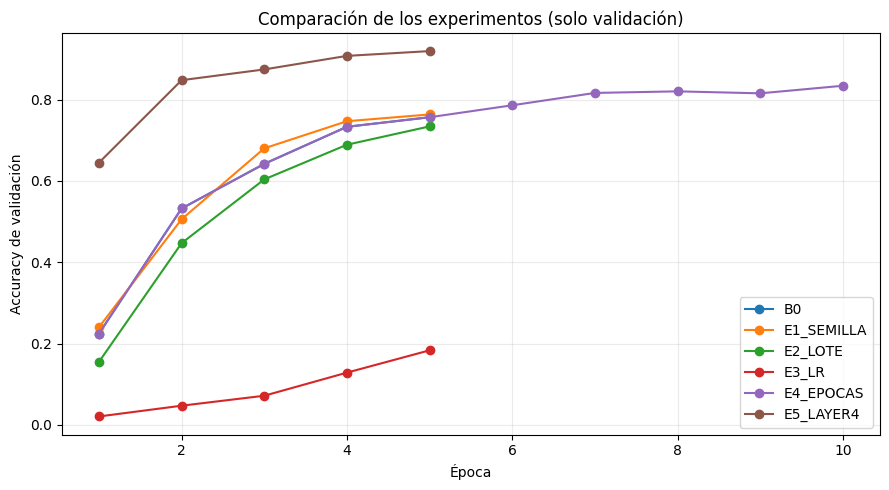

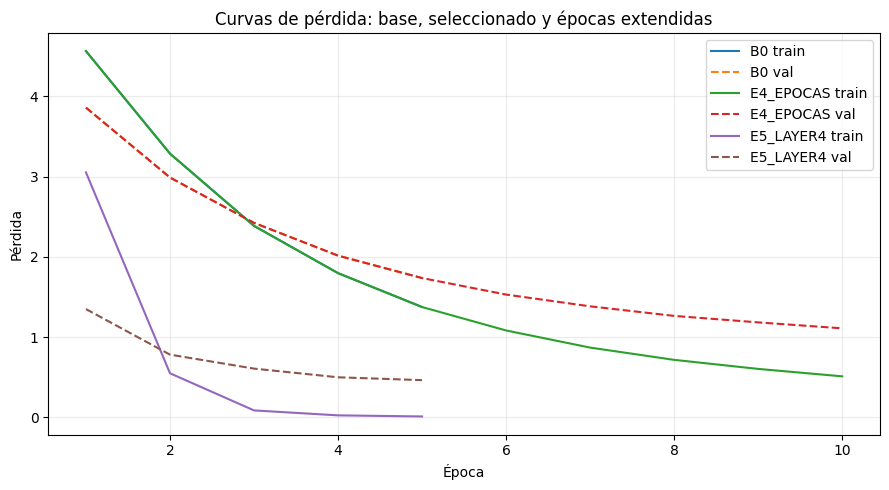

[6/10] Selección concluida; prueba continúa intacta en esta ejecución


In [6]:
print('[6/10] Comparación y selección usando SOLO validación')
assert len(RESULTS)==len(EXPERIMENTS),'Faltan ejecuciones; NO seleccionar modelo'
summary=pd.DataFrame([{k:v for k,v in r.items() if k not in ('history','checkpoint')} for r in RESULTS])
summary=summary[['id','seed','batch_size','lr','epochs','finetune_layer4',
                 'trainable','best_epoch','best_val_acc','best_val_loss','seconds']]
print(summary.to_string(index=False))
summary.to_csv(EVID_DIR/'comparativa_validacion.csv',index=False)
# criterio fijado: mayor accuracy; empate menor val_loss; empate menos entrenables;
# empate id lexicográfico para desempate determinista.
ordered=sorted(RESULTS,key=lambda r:(-r['best_val_acc'],r['best_val_loss'],r['trainable'],r['id']))
WINNER=ordered[0]
print('CONFIGURACIÓN SELECCIONADA:',WINNER['id'])
print('Criterio: mayor val_acc; empate menor val_loss, menos parámetros entrenables e ID')
print('Checkpoint seleccionado:',WINNER['checkpoint'])
fig,ax=plt.subplots(figsize=(9,5))
for r in RESULTS:
    ax.plot([h['epoch'] for h in r['history']],
            [h['val_acc'] for h in r['history']],marker='o',label=r['id'])
ax.set(xlabel='Época',ylabel='Accuracy de validación',title='Comparación de los experimentos (solo validación)')
ax.grid(alpha=0.25);ax.legend();fig.tight_layout()
fig.savefig(EVID_DIR/'curvas_validacion.png',dpi=160)
plt.show()
fig,ax=plt.subplots(figsize=(9,5))
for r in RESULTS:
    if r['id'] in ('B0',WINNER['id'],'E4_EPOCAS'):
        ax.plot([h['epoch'] for h in r['history']],[h['train_loss'] for h in r['history']],label=r['id']+' train')
        ax.plot([h['epoch'] for h in r['history']],[h['val_loss'] for h in r['history']],linestyle='--',label=r['id']+' val')
ax.set(xlabel='Época',ylabel='Pérdida',title='Curvas de pérdida: base, seleccionado y épocas extendidas')
ax.grid(alpha=0.25);ax.legend();fig.tight_layout()
fig.savefig(EVID_DIR/'curvas_perdida.png',dpi=160)
plt.show()
print('[6/10] Selección concluida; prueba continúa intacta en esta ejecución')

### Curvas y selección
1. En B0, pérdida de entrenamiento 4.5653 → 1.3747 y validación 3.8607 → 1.7359. E4 terminó con pérdida de validación 1.1090; E5, 0.4631. Las curvas de E5 muestran una separación entre pérdidas de entrenamiento y validación, pero la validación sigue mejorando durante las cinco épocas. Esa separación, por sí sola, no demuestra deterioro por sobreajuste.
2. Accuracy es la proporción de aciertos; no describe qué clases se confunden. Por eso se registraron también métricas por clase, matriz de confusión y ejemplos erróneos.
3. Validación: B0 75.69%, E1 76.37%, E2 73.43%, E3 18.33%, E4 83.43%, E5 91.96%. Se eligió E5_LAYER4 por mayor accuracy; los desempates previstos fueron menor pérdida, menos parámetros entrenables e ID. Se evaluó prueba después de elegirlo: Top-1 88.8600% y Top-3 94.9748%. Se conocían resultados históricos de prueba; no se utilizaron para elegir configuración dentro de esta ejecución.

## 6. Verificación del ganador y evaluación final en prueba

In [7]:
print('[7/10] Reconstrucción independiente del ganador y AUDITORÍA FINAL')
assert WINNER['checkpoint'] and Path(WINNER['checkpoint']).exists()
ckpt=torch.load(WINNER['checkpoint'],map_location='cpu',weights_only=True)
assert ckpt['config']['id']==WINNER['id']
FINAL_MODEL=build_model(ckpt['config']['finetune_layer4'])
FINAL_MODEL.load_state_dict(ckpt['state_dict'],strict=True)
FINAL_MODEL.eval()
FINAL_AUDIT=audit_model(FINAL_MODEL,print_details=True)
assert FINAL_AUDIT['total']==11228838
assert FINAL_AUDIT['trainable']==ckpt['architecture']['trainable']
print('Comparación base vs final:',ARQUITECTURA_BASE['trainable'],'->',FINAL_AUDIT['trainable'],'entrenables')

print('[8/10] Comienza evaluación FINAL de prueba (después de seleccionar).')
test_loader=DataLoader(test_ds,batch_size=WINNER['batch_size'],shuffle=False,num_workers=NUM_WORKERS)
loss_fn=nn.CrossEntropyLoss()
TEST_LOSS_SUM=0.;n=0; TOP1=0;TOP3=0
real=[];pred=[];top3_ids=[];probs_saved=[]
with torch.no_grad():
    for x,y in test_loader:
        logits=FINAL_MODEL(x.to(DEVICE))
        loss=loss_fn(logits,y.to(DEVICE))
        probabilities=torch.softmax(logits,dim=1).cpu()
        p3=probabilities.topk(3,dim=1).indices
        guess=p3[:,0]
        TEST_LOSS_SUM+=loss.item()*len(y);n+=len(y)
        TOP1+=(guess==y).sum().item()
        TOP3+=(p3==y[:,None]).any(dim=1).sum().item()
        real.extend(y.tolist());pred.extend(guess.tolist())
        top3_ids.extend(p3.tolist());probs_saved.extend(probabilities.tolist())
assert n==len(test_ds)
TEST_METRICS={'loss':TEST_LOSS_SUM/n,'top1':TOP1/n,'top3':TOP3/n,'examples':n}
print('Prueba final:',TEST_METRICS)
print('ADVERTENCIA: se conocían resultados históricos de test de una ejecución anterior. No se usaron para selección en este notebook.')

[7/10] Reconstrucción independiente del ganador y AUDITORÍA FINAL
Parámetros: {'total': 11228838, 'trainable': 8446054, 'frozen': 2782784}
  conv1      (1, 3, 224, 224) -> (1, 64, 112, 112)
  bn1        (1, 64, 112, 112) -> (1, 64, 112, 112)
  relu       (1, 64, 112, 112) -> (1, 64, 112, 112)
  maxpool    (1, 64, 112, 112) -> (1, 64, 56, 56)
  layer1     (1, 64, 56, 56) -> (1, 64, 56, 56)
  layer2     (1, 64, 56, 56) -> (1, 128, 28, 28)
  layer3     (1, 128, 28, 28) -> (1, 256, 14, 14)
  layer4     (1, 256, 14, 14) -> (1, 512, 7, 7)
  avgpool    (1, 512, 7, 7) -> (1, 512, 1, 1)
  fc         (1, 512) -> (1, 102)
Comparación base vs final: 52326 -> 8446054 entrenables
[8/10] Comienza evaluación FINAL de prueba (después de seleccionar).
Prueba final: {'loss': 0.549196594654496, 'top1': 0.8885997723207025, 'top3': 0.9497479264921126, 'examples': 6149}
ADVERTENCIA: se conocían resultados históricos de test de una ejecución anterior. No se usaron para selección en este notebook.


## 7. Matriz de confusión, errores y predicciones

[9/10] Métricas por clase, matriz y análisis de errores
              precision    recall  f1-score   support

      Flor 1       0.45      1.00      0.62        20
      Flor 2       1.00      0.95      0.97        40
      Flor 3       0.38      0.45      0.41        20
      Flor 4       0.72      0.58      0.65        36
      Flor 5       1.00      0.80      0.89        45
      Flor 6       0.96      0.96      0.96        25
      Flor 7       0.86      0.95      0.90        20
      Flor 8       0.96      1.00      0.98        65
      Flor 9       0.68      0.88      0.77        26
     Flor 10       0.93      1.00      0.96        25
     Flor 11       0.87      0.79      0.83        67
     Flor 12       0.94      0.93      0.93        67
     Flor 13       0.94      1.00      0.97        29
     Flor 14       0.90      1.00      0.95        28
     Flor 15       0.94      1.00      0.97        29
     Flor 16       0.61      0.90      0.73        21
     Flor 17       0.98  

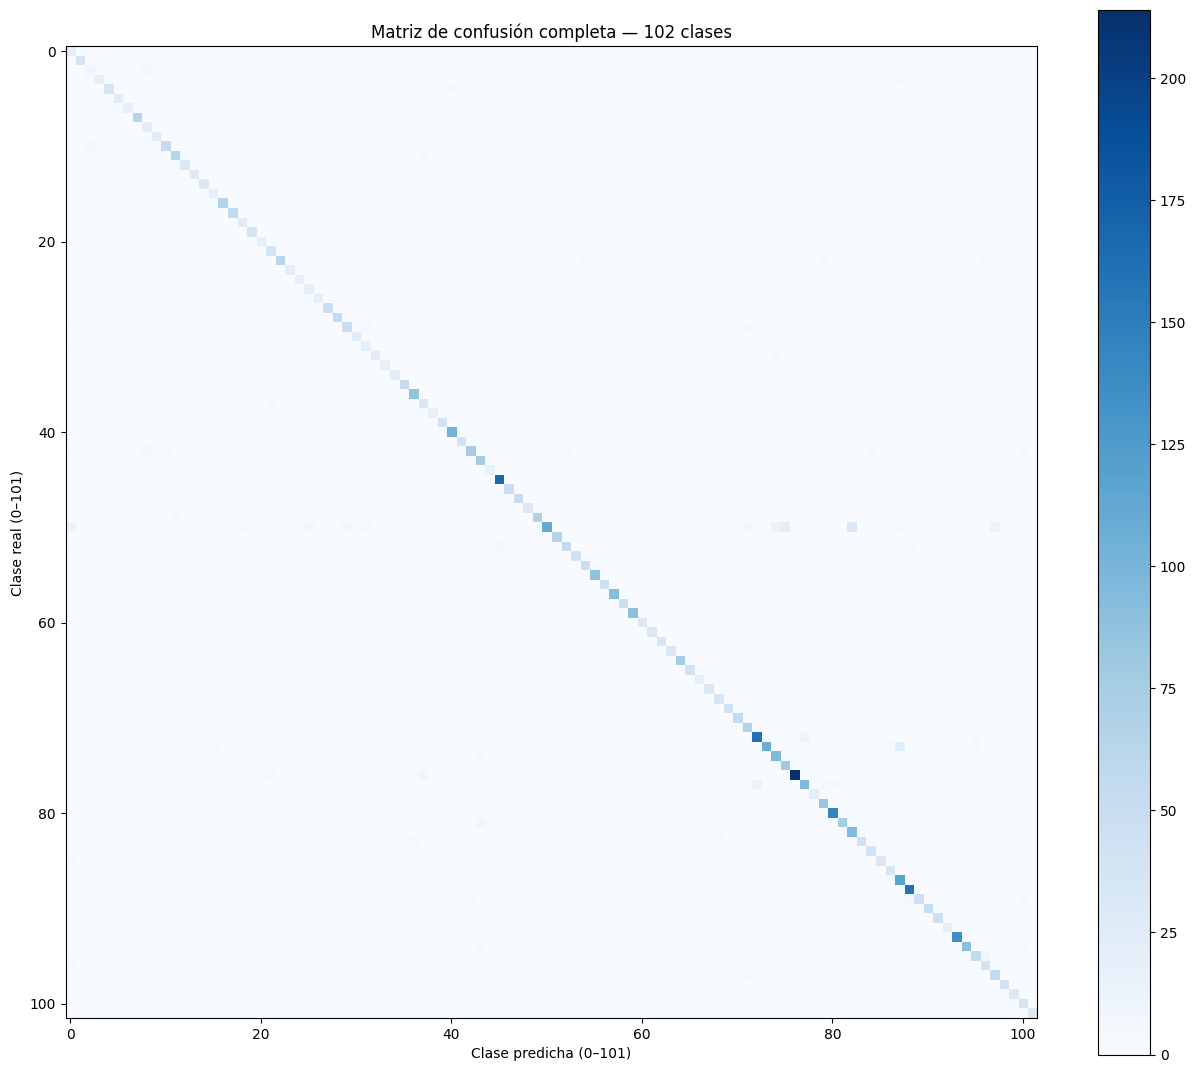

Dos confusiones más frecuentes (reales -> predichas):
  Flor 51 -> Flor 83: 31 casos
  Flor 74 -> Flor 88: 23 casos
Errores disponibles: 685


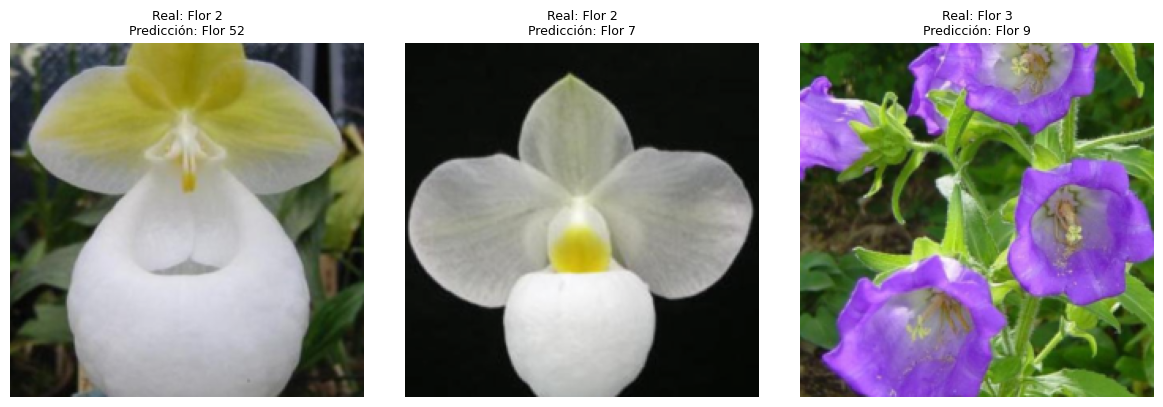

Cinco predicciones de prueba:
  ejemplo 0: real=Flor 1; pred=Flor 1; Top-3=Flor 1 (0.861), Flor 19 (0.033), Flor 55 (0.008)
  ejemplo 1: real=Flor 1; pred=Flor 1; Top-3=Flor 1 (0.767), Flor 34 (0.026), Flor 86 (0.024)
  ejemplo 2: real=Flor 1; pred=Flor 1; Top-3=Flor 1 (0.509), Flor 34 (0.033), Flor 67 (0.029)
  ejemplo 3: real=Flor 1; pred=Flor 1; Top-3=Flor 1 (0.982), Flor 76 (0.004), Flor 86 (0.003)
  ejemplo 4: real=Flor 1; pred=Flor 1; Top-3=Flor 1 (0.996), Flor 76 (0.001), Flor 91 (0.001)
Top-1 de toda prueba: 0.8886 | Top-3: 0.9497


In [8]:
print('[9/10] Métricas por clase, matriz y análisis de errores')
cm=confusion_matrix(real,pred,labels=list(range(NUM_CLASSES)))
report=classification_report(real,pred,labels=list(range(NUM_CLASSES)),target_names=CLASSES,zero_division=0,output_dict=True)
pd.DataFrame(report).transpose().to_csv(EVID_DIR/'metricas_por_clase.csv')
print(classification_report(real,pred,labels=list(range(NUM_CLASSES)),target_names=CLASSES,zero_division=0))
fig,ax=plt.subplots(figsize=(13,11))
im=ax.imshow(cm,cmap='Blues',interpolation='nearest')
fig.colorbar(im,ax=ax)
ax.set(xlabel='Clase predicha (0–101)',ylabel='Clase real (0–101)',title='Matriz de confusión completa — 102 clases')
fig.tight_layout();fig.savefig(EVID_DIR/'matriz_confusion.png',dpi=180);plt.show()
cm_errors=cm.copy();np.fill_diagonal(cm_errors,0)
error_pairs=sorted([(int(cm_errors[a,b]),a,b) for a in range(NUM_CLASSES)
                    for b in range(NUM_CLASSES) if a!=b and cm_errors[a,b]>0],reverse=True)
print('Dos confusiones más frecuentes (reales -> predichas):')
for count,a,b in error_pairs[:2]:print(f'  {CLASSES[a]} -> {CLASSES[b]}: {count} casos')
incorrect=[i for i,(r,p) in enumerate(zip(real,pred)) if r!=p]
print('Errores disponibles:',len(incorrect))
assert len(incorrect)>=3,'No existen tres errores para analizar; documentar esta limitación'
# La transformación incluye normalización; invertirla solo para mostrar imágenes.
mean=np.array([0.485,0.456,0.406])[:,None,None]
std=np.array([0.229,0.224,0.225])[:,None,None]
fig,axes=plt.subplots(1,3,figsize=(12,4))
for ax,i in zip(axes,incorrect[:3]):
    x,y=test_ds[i]
    displayed=np.clip(x.numpy()*std+mean,0,1).transpose(1,2,0)
    ax.imshow(displayed);ax.axis('off')
    ax.set_title(f'Real: {CLASSES[y]}\nPredicción: {CLASSES[pred[i]]}',fontsize=9)
fig.tight_layout();fig.savefig(EVID_DIR/'tres_errores.png',dpi=160);plt.show()
print('Cinco predicciones de prueba:')
for i in range(min(5,len(test_ds))):
    ids=top3_ids[i]
    top3_str=', '.join(f'{CLASSES[j]} ({probs_saved[i][j]:.3f})' for j in ids)
    print(f'  ejemplo {i}: real={CLASSES[real[i]]}; pred={CLASSES[pred[i]]}; Top-3={top3_str}')
print('Top-1 de toda prueba:',f"{TEST_METRICS['top1']:.4f}",'| Top-3:',f"{TEST_METRICS['top3']:.4f}")

### Errores y métricas
1. Las dos confusiones más frecuentes registradas fueron Flor 51 → Flor 83 (31 casos) y Flor 74 → Flor 88 (23 casos). La matriz y estas frecuencias identifican patrones de error; no establecen sus causas visuales.
2. Precisión es aciertos entre predicciones de una clase; recall es aciertos entre ejemplos reales de esa clase; F1 es su media armónica. El reporte por clase está guardado en `evidencias/metricas_por_clase.csv`.
3. En el primer error (Flor 2 → Flor 52) se observa una flor blanca con región superior amarilla y un pétalo inferior grande; en el segundo (Flor 2 → Flor 7), pétalos blancos sobre fondo oscuro y un centro amarillo; en el tercero (Flor 3 → Flor 9), varias corolas moradas en forma de campana y vegetación alrededor. Los dos primeros comparten etiqueta real, pero difieren en encuadre, fondo y distribución del amarillo. El tercero contiene varias flores, a diferencia de los primeros planos anteriores. Estas diferencias son observables en las imágenes; no demuestran por sí solas la causa de las predicciones incorrectas.
4. En los cinco ejemplos impresos la etiqueta real es Flor 1 y aparece en primera posición; por tanto también pertenece al Top-3. Esta muestra no representa todas las clases.
5. En las 6,149 imágenes: 5,464 aciertos Top-1 y 685 errores; Top-1 88.8600%, Top-3 94.9748%. Top-3 supera Top-1 en 6.1148 puntos porcentuales. Las probabilidades softmax no acreditan calibración.

## 8. Guardado final, nueva carga e inferencia reproducible

In [11]:
print('[10/10] Exportación final y comprobación de carga independiente')
EXPORT_PATH=ROOT/'modelo_entrenado.pth'

# Convertir cualquier objeto complejo de versión (como TorchVersion) a strings estándar
versions_safe = {k: str(v) for k, v in VERSIONS.items()}

FINAL_META={'architecture':'resnet18','weights_enum':'ResNet18_Weights.DEFAULT',
            'num_classes':NUM_CLASSES,'class_labels':CLASSES,
            'transform_repr':str(TRANSFORM),'input_shape':[3,224,224],
            'best_experiment':WINNER['id'],'best_epoch':WINNER['best_epoch'],
            'config':WINNER and {key:WINNER[key] for key in ('seed','batch_size','lr','epochs','finetune_layer4')},
            'versions':versions_safe,'device_used':str(DEVICE),
            'selection':'validation accuracy > val loss > fewer trainable params > id',
            'test_metrics':TEST_METRICS,'audit':{'total':FINAL_AUDIT['total'],
                                                'trainable':FINAL_AUDIT['trainable'],
                                                'frozen':FINAL_AUDIT['frozen']}}
# Los modelos/transformaciones no son objetos serializados: se reconstruyen en código.
torch.save({'state_dict':FINAL_MODEL.state_dict(),'metadata':FINAL_META},EXPORT_PATH)
with (ROOT/'metadata.json').open('w',encoding='utf8') as f:	json.dump(FINAL_META,f,ensure_ascii=False,indent=2)
with (ROOT/'resultados_experimentos.json').open('w',encoding='utf8') as f:
    json.dump(RESULTS,f,ensure_ascii=False,indent=2)
RESTORED=torch.load(EXPORT_PATH,map_location='cpu',weights_only=False)
RESTORED_MODEL=build_model(RESTORED['metadata']['config']['finetune_layer4'])
RESTORED_MODEL.load_state_dict(RESTORED['state_dict'],strict=True)
RESTORED_MODEL.eval()
x0,y0=test_ds[0]
with torch.no_grad():
    original=FINAL_MODEL(x0.unsqueeze(0).to(DEVICE))
    restored=RESTORED_MODEL(x0.unsqueeze(0).to(DEVICE))
assert torch.allclose(original,restored,atol=1e-6,rtol=1e-5),'Discrepancia en predicción al cargar checkpoint'
print('Modelo restaurado correctamente; predicción coincide con el original')
print('Real:',CLASSES[y0],'| Pred:',CLASSES[int(restored.argmax(1).item())])
print('Guardado:',EXPORT_PATH)
print('Metadatos:',ROOT/'metadata.json')
print('Evidencias:',EVID_DIR)
print('Entrenamientos realizados:',len(RESULTS),'| modelo final:',WINNER['id'])
print('FIN: entrega técnica producida; comprobar archivos y descargar carpeta desde Colab.')

[10/10] Exportación final y comprobación de carga independiente
Modelo restaurado correctamente; predicción coincide con el original
Real: Flor 1 | Pred: Flor 1
Guardado: /content/flowers102_reentrenamiento_independiente/modelo_entrenado.pth
Metadatos: /content/flowers102_reentrenamiento_independiente/metadata.json
Evidencias: /content/flowers102_reentrenamiento_independiente/evidencias
Entrenamientos realizados: 6 | modelo final: E5_LAYER4
FIN: entrega técnica producida; comprobar archivos y descargar carpeta desde Colab.


### Guardado y comprobación de carga
1. Se exportó `modelo_entrenado.pth` con `state_dict` y metadatos: arquitectura, clases, preprocesamiento, configuración, versiones y métricas. El modelo se reconstruyó y cargó estrictamente; la predicción del ejemplo comprobado coincidió con la del modelo anterior a la exportación.
2. `softmax` convierte logits en valores positivos que suman uno; una probabilidad alta puede corresponder a una clasificación equivocada.
3. E5 habilitó layer4 y fc: 8,446,054 parámetros entrenables frente a 52,326 en B0, y mejoró validación de 75.6863% a 91.9608%. Los cinco ejemplos impresos fueron clasificados como Flor 1, coincidiendo con su etiqueta.
4. Los artefactos exportados son el modelo final, sus metadatos, resultados de seis experimentos y evidencias. La igualdad comprobada al restaurar el modelo no demuestra reproducibilidad bit a bit de un nuevo entrenamiento ni calibración de las probabilidades.

In [ ]:
# Celda auxiliar de empaquetado: no registra ejecución en esta sesión.
print('[11/11] Empaquetado de reentrenamiento')
from zipfile import ZipFile, ZIP_DEFLATED
output_zip=ROOT.parent/'Reentrenamiento_Flores_Independiente.zip'
archivos=[p for p in ROOT.rglob('*') if p.is_file() and 'checkpoints' not in p.parts and 'datos' not in p.parts]
assert (ROOT/'modelo_entrenado.pth').exists() and (ROOT/'metadata.json').exists()
with ZipFile(output_zip,'w',ZIP_DEFLATED) as z:
    for p in archivos: z.write(p,arcname=p.relative_to(ROOT))
with ZipFile(output_zip) as z: assert z.testzip() is None
print('REENTRENAMIENTO COMPLETO:',output_zip,'| archivos:',len(archivos))
try:
    from google.colab import files
    files.download(str(output_zip))
except ImportError:
    print('Archivo generado localmente:',output_zip)
